In order to get familiar with Pytorch, we can work with the most basic unit in pytorch: tensors. Notice we can also freely convert between numpy arrays and tensors. To allow us to connect other scientific computing/data science libs like scikit-learn, scipy, etc.



## How to work with Tensors in Pytorch

In [4]:
import torch
import numpy as np

np.set_printoptions(precision=3) # obv just setting how np should print results to std out (ie terminal) for readability


a = [1,2,3] # just made a list that we will convert to a torch tensor
b = np.array([4,5,6], dtype=np.int32) # we make an np array with int32 data type that we will convert to a torch tensor
t_a = torch.tensor(a) # we just put the list called 'a' into the function to make a torch tensor
t_b = torch.tensor(b) # we can do the same for the np array

# now lets see what they look like
print(t_a)
print(t_b)

# Notice how it automatically infers that we specified the inputs as integers even as a int32 for the np array

tensor([1, 2, 3])
tensor([4, 5, 6], dtype=torch.int32)


In [5]:
# Now we will use some of the helper functions to make certain types of tensors that are commonly used
# like a tensor made of ones with an arbitrary dim or a tensor of zeros, random nums, etc. Just look at
# the docs when you want to see if there's any easy way to make a specific kind of tensor.

t_ones = torch.ones(2,3) # here we made a matrix of size 2,3
t_rand = torch.rand(2,3,3) # here we made a tensor of rand floats between 0-1 of size 2,3,3 (that makes it a 3D tensor)

print(t_ones)
print(t_rand)

tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([[[0.5338, 0.0323, 0.8674],
         [0.7281, 0.6177, 0.1815],
         [0.4006, 0.6150, 0.3792]],

        [[0.7840, 0.3680, 0.8334],
         [0.1471, 0.9686, 0.5702],
         [0.1324, 0.0264, 0.1932]]])


In [15]:
# we can change the data type by using the `.to` method on the tensor.

t_b_new_dtype = t_b.to(torch.int64)
print(f"t_b dtype: {t_b.dtype} -> t_a_new_dtype: {t_b_new_dtype.dtype}")

# we can "rotate"/transpose the tensor using the `transpose method`
t = torch.rand(3, 5)
t_transpose = torch.transpose(t, 0, 1) # we specify how we want to rotate/transpose this tensor. Very simple in 2D. 
print(f"t.shape: {t.shape} --> t_transpose.shape: {t_transpose.shape}") # notice how the size got "flipped"

# We can reshape a 30 elem vec to a 5x6 matrix
t = torch.zeros(30)
t_reshape = t.reshape(5,6)
print(t_reshape.shape)

# Here we remove unnecessary dims (dims that have size 1 are not needed)
t = torch.zeros(1,2,1,4,1)
t_squeeze = torch.squeeze(t, 2)
print(t.shape, '-->', t_squeeze.shape)

t_b dtype: torch.int32 -> t_a_new_dtype: torch.int64
t.shape: torch.Size([3, 5]) --> t_transpose.shape: torch.Size([5, 3])
torch.Size([5, 6])
torch.Size([1, 2, 1, 4, 1]) --> torch.Size([1, 2, 4, 1])


In [37]:
# We can easily apply mathematical operations to tensors, especially from lin alg.
# the most common operations you will apply will be elem-wise product, matrix multplication, and computing
# the norm of a tensor.

torch.manual_seed(1)
t1 = 2 * torch.rand(5,2) - 1 # create tensor with size 5x2 from random unif dist and scale by 2 shift to range [-3,1]
t2 = torch.normal(mean=0, std=1, size=(5,2)) # create a tensor of size 5x2 with elems sampled from normal dist
print(f"{t1=}")
print(f"{t2=}")

t3 = torch.multiply(t1,t2)
print(f"t1 x t2 = {t3}")

t4 = torch.mean(t1, axis=0)
print(f"Mean of t4 across first dim, 0, of t1: {t4}")
print("Remember the first axis/dim of t1 is len 5. So we take mean across dim 0 \
    with len 5 and end with a tensor of size 1x2 from 5x2")

# remember to transpose we switch dim sizes (5x2) for dim 0 (ie 5) and 1 (ie 2).
# for matrix multiplication, we need to have sizes match like (m,n) x (n, m) = (m,m) 
t5 = torch.matmul(t1, torch.transpose(t2, 0, 1))
print(t5)
t6 = torch.matmul(torch.transpose(t1, 0, 1), t2)
print(t6)

# Here we can take the L2 norm across a specific dim of a matrix (0 or 1) by using the linalg.norm func.
norm_t1 = torch.linalg.norm(t1, ord=2, dim=1)
print(norm_t1)

t1=tensor([[ 0.5153, -0.4414],
        [-0.1939,  0.4694],
        [-0.9414,  0.5997],
        [-0.2057,  0.5087],
        [ 0.1390, -0.1224]])
t2=tensor([[ 0.8590,  0.7056],
        [-0.3406, -1.2720],
        [-1.1948,  0.0250],
        [-0.7627,  1.3969],
        [-0.3245,  0.2879]])
t1 x t2 = tensor([[ 0.4426, -0.3114],
        [ 0.0660, -0.5970],
        [ 1.1249,  0.0150],
        [ 0.1569,  0.7107],
        [-0.0451, -0.0352]])
Mean of t4 across first dim, 0, of t1: tensor([-0.1373,  0.2028])
Remember the first axis/dim of t1 is len 5. So we take mean across dim 0     with len 5 and end with a tensor of size 1x2 from 5x2
tensor([[ 0.1312,  0.3860, -0.6267, -1.0096, -0.2943],
        [ 0.1647, -0.5310,  0.2434,  0.8035,  0.1980],
        [-0.3855, -0.4422,  1.1399,  1.5558,  0.4781],
        [ 0.1822, -0.5771,  0.2585,  0.8676,  0.2132],
        [ 0.0330,  0.1084, -0.1692, -0.2771, -0.0804]])
tensor([[ 1.7453,  0.3392],
        [-1.6038, -0.2180]])
tensor([0.6785, 0.5078, 1.1162,

In [43]:
torch.manual_seed(1)
t = torch.rand(6)
# print(t)

# We can split the (6,) size tensor into a 3 and end up with 3 tensors of size 2 using chunk
t_splits = torch.chunk(t,3)
# [item.numpy() for item in t_splits]
print(t_splits) # see we have 3 tensors of size 2

# we can also choose how to split it up by specifying how to split 5 into 3 and 2.
t = torch.rand(5)
t_splits = torch.split(t, split_size_or_sections=[3,2])
print(t_splits) # notice we have a tensor of len 3 and 2.

(tensor([0.7576, 0.2793]), tensor([0.4031, 0.7347]), tensor([0.0293, 0.7999]))
(tensor([0.3971, 0.7544, 0.5695]), tensor([0.4388, 0.6387]))


In [47]:
# Here we concatenate and stack tensors. 

# Concatenate lets us add tensors to an existing dimension.
A = torch.ones(3)
B = torch.zeros(2)
C = torch.cat((A,B),0)
print(C)

# Stack lets us add tensors in a new dimension
D = torch.stack((C,C),1)
print(D)

tensor([1., 1., 1., 0., 0.])
tensor([[1., 1.],
        [1., 1.],
        [1., 1.],
        [0., 0.],
        [0., 0.]])


## Building Input Pipelines in Pytorch

Pytorch uses the term batch instead of mini-batch to refer to the case where we load a chunk of data from the dataset and then update the model, typically called mini-batch gradient descent.

In [54]:
# This is an example where we can load the entire dataset in memory as opposed to having to load it
# batch by batch.

# we can use the dataloader obj to easily apply transformations that we would need to apply 
# to samples from the dataset in order to prevent overfitting.
from torch.utils.data import DataLoader
t = torch.arange(6, dtype=torch.float32)
# Here we instantiate the dataloader with our dataset
dataloader = DataLoader(t)

# we can iterate through the items 
for item in dataloader:
    print(item)


# Here we load the entire dataset in as batches which is how we will often train models
# because the datasets are too large to load into memory.
dataloader = DataLoader(t, batch_size=3, drop_last=False)
for i, batch in enumerate(dataloader, 1):
    print(f'batch {i}', batch)
    

tensor([0.])
tensor([1.])
tensor([2.])
tensor([3.])
tensor([4.])
tensor([5.])
batch 1 tensor([0., 1., 2.])
batch 2 tensor([3., 4., 5.])


In [61]:
# We can create a joint dataset where we combine two tensors.
# This is useful in examplates where we have one tensor for features and another for labels.
# This is the classic way we store data that we will use to train a model.

t_x = torch.rand([4,3], dtype=torch.float32)
t_y = torch.arange(4)

# Here we create a custom dataset class that can be used by the dataloader obj we import from Pytorch
from torch.utils.data import Dataset

# A custom Dataset class must define an __init__ method and __getitem__ method that will return 
# a sample given an index (idx).
class JointDataset(Dataset):
    def __init__(self, x, y):
        self.x = x
        self.y = y
        
    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

from torch.utils.data import TensorDataset

joint_dataset = TensorDataset(t_x, t_y)

for example in joint_dataset:
    print(' x: ', example[0], ' y: ', example[1])

 x:  tensor([0.5896, 0.2873, 0.3486])  y:  tensor(0)
 x:  tensor([0.9579, 0.4075, 0.7819])  y:  tensor(1)
 x:  tensor([0.7165, 0.1768, 0.0748])  y:  tensor(2)
 x:  tensor([0.9799, 0.5261, 0.8427])  y:  tensor(3)


In [74]:
torch.manual_seed(1)
# Here we create a batch size of two for our data and shuffle the features and labels together so
# we don't lose track of them.
joint_dataloader = DataLoader(dataset=joint_dataset, batch_size=2, shuffle=True)

for i, batch in enumerate(joint_dataloader, 1):
    print(f'batch {i}', '\nx: ', batch[0], \
         '\ny:', batch[1])

batch 1 
x:  tensor([[0.7165, 0.1768, 0.0748],
        [0.5896, 0.2873, 0.3486]]) 
y: tensor([2, 0])
batch 2 
x:  tensor([[0.9579, 0.4075, 0.7819],
        [0.9799, 0.5261, 0.8427]]) 
y: tensor([1, 3])


In [75]:
import pathlib

imgdir_path = pathlib.Path('data/cat_dog_imgs')
file_list = sorted([str(path) for path in imgdir_path.glob('*.jpg')])
print(file_list)

['data/cat_dog_imgs/cat-01.jpg', 'data/cat_dog_imgs/cat-02.jpg', 'data/cat_dog_imgs/cat-03.jpg', 'data/cat_dog_imgs/dog-01.jpg', 'data/cat_dog_imgs/dog-02.jpg', 'data/cat_dog_imgs/dog-03.jpg']


Image shape: (900, 1200, 3)
Image shape: (900, 1200, 3)
Image shape: (900, 742, 3)
Image shape: (800, 1200, 3)
Image shape: (800, 1200, 3)
Image shape: (900, 1200, 3)


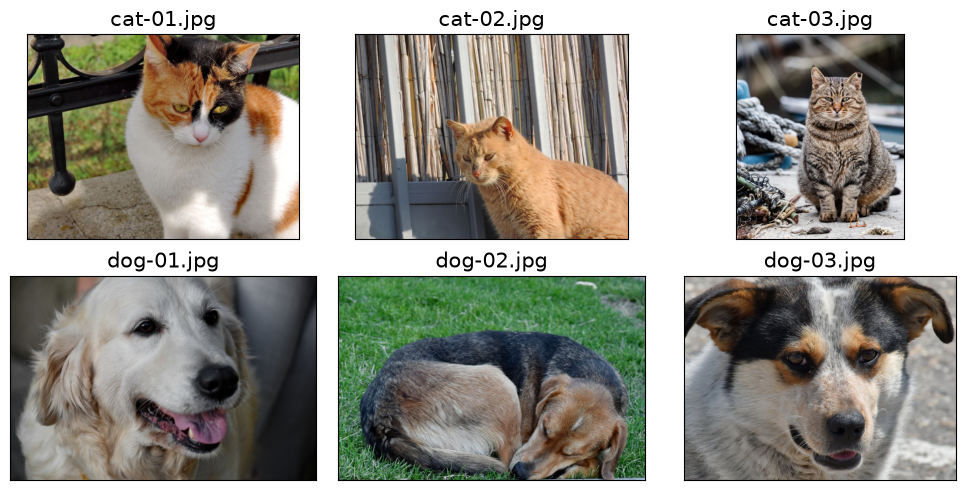

In [89]:
# Here we do a quick & dirty viz of our data to get a feel for what it looks like
# We see that the images have different aspect ratios, the file names contain the label
# and doggos and cats are very adorable.

import matplotlib.pyplot as plt
import os
from PIL import Image
fig = plt.figure(figsize=(10,5))
for i, file in enumerate(file_list):
    img = Image.open(file)
    print('Image shape:', np.array(img).shape)
    ax = fig.add_subplot(2,3, i+1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.imshow(img)
    ax.set_title(os.path.basename(file), size=15)

plt.tight_layout()
plt.show()

In [90]:
# We just extract the label from the file name by parsing the list of file names 
# and storing the result in labels

labels = [1 if 'dog' in os.path.basename(file) else 0 for file in file_list]
print(labels)

[0, 0, 0, 1, 1, 1]


In [106]:
# Here we create a custom dataset class that can be used by the dataloader obj we import from Pytorch
from torch.utils.data import Dataset
from PIL import Image

class ImageDataset(Dataset):
    def __init__(self, img_paths, labels, transform=None):
        self.img_paths: list[str] = img_paths
        self.labels = labels
        self.transform = transform

    def __getitem__(self, idx):
        img = Image.open(self.img_paths[idx])
        file = self.img_paths[idx]
        if self.transform is not None:
            img = self.transform(img)
        label = self.labels[idx]
        return file, img, label  

    def __len__(self):
        if len(self.img_paths) != len(self.labels):
            raise ValueError
        return len(self.img_paths)

# Here we created a custom Dataset obj that we will use to load and store our data
img_dataset = ImageDataset(file_list, labels)
for file, _, label in img_dataset:
    print(file, label)

data/cat_dog_imgs/cat-01.jpg 0
data/cat_dog_imgs/cat-02.jpg 0
data/cat_dog_imgs/cat-03.jpg 0
data/cat_dog_imgs/dog-01.jpg 1
data/cat_dog_imgs/dog-02.jpg 1
data/cat_dog_imgs/dog-03.jpg 1


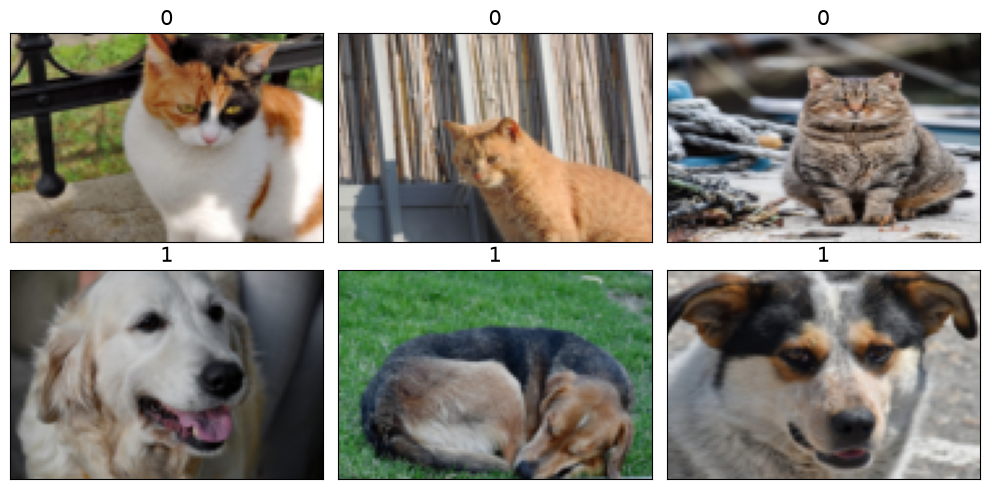

In [107]:
import torchvision.transforms.v2 as transforms

img_height, img_width = 80, 120
transform = transforms.Compose([
    transforms.ToImage(), # convert to tensor
    transforms.Resize((img_height, img_width)),
])

image_dataset = ImageDataset(file_list, labels, transform)
fig = plt.figure(figsize=(10,5))
for i, example in enumerate(image_dataset):
    ax = fig.add_subplot(2,3, i+1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.imshow(example[1].numpy().transpose((1,2,0)))
    ax.set_title(f'{example[2]}', size=15)

plt.tight_layout()
plt.show()

In [110]:
from torchvision import datasets

celeba_dataset = datasets.CelebA('data/', split='train', target_type='attr', download=True)

True
(<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=178x218 at 0x71A803F79BD0>, tensor([0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0,
        1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1]))


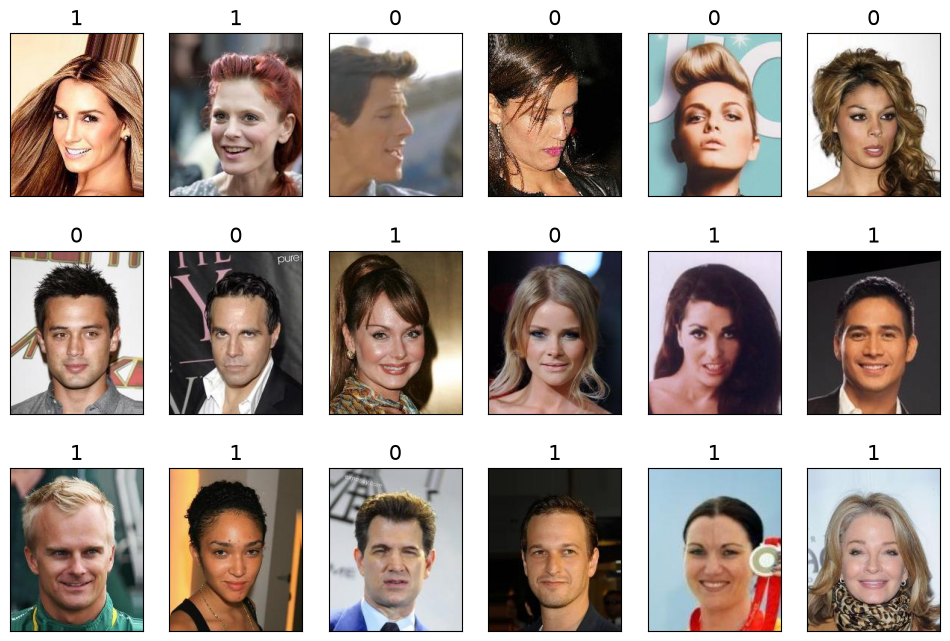

In [120]:
print(isinstance(celeba_dataset, torch.utils.data.Dataset))

example = next(iter(celeba_dataset))
print(example)

from itertools import islice
fig = plt.figure(figsize=(12,8))
for i, (img, attr) in islice(enumerate(celeba_dataset), 18):
    ax = fig.add_subplot(3,6, i+1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.imshow(img)
    ax.set_title(f'{attr[31]}', size=15)

plt.show()

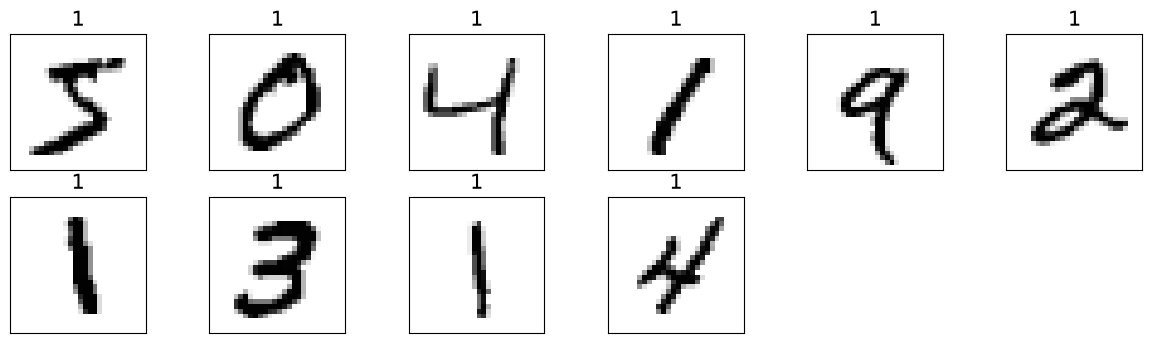

In [123]:
mnist_dataset = datasets.MNIST('data/','train',download=True)
fig = plt.figure(figsize=(15,6))
for i, (img, label) in islice(enumerate(mnist_dataset), 10):
    ax = fig.add_subplot(3,6, i+1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.imshow(img, cmap='gray_r')
    ax.set_title(f'{attr[31]}', size=15)
plt.show()

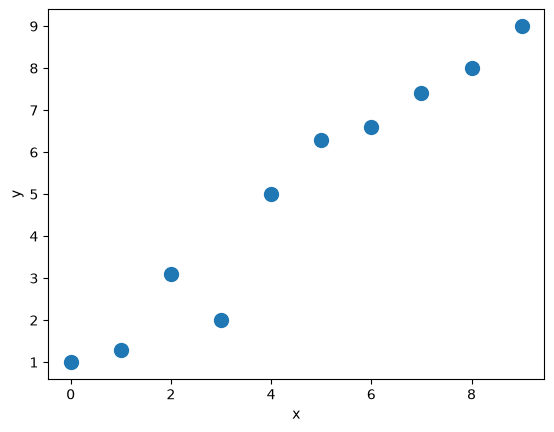

In [136]:
X_train = np.arange(10, dtype='float32').reshape((10,1))
y_train = np.array([1.0, 1.3, 3.1, 2.0, 5.0, 6.3, 6.6, 7.4, 8.0, 9.0], dtype='float32')

plt.plot(X_train, y_train, 'o', markersize=10)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [137]:
from torch.utils.data import TensorDataset

X_train_norm = (X_train - np.mean(X_train)) / np.std(X_train)
X_train_norm = torch.from_numpy(X_train_norm)
y_train = torch.from_numpy(y_train).float()
train_ds = TensorDataset(X_train_norm, y_train)
batch_size = 1
train_dl = DataLoader(train_ds, batch_size, shuffle=True)